# Công đoạn 06 — Huấn luyện và so sánh mô hình
## 1. Mục tiêu
So sánh 13 cấu hình phân loại **ngành đang học** bằng 5-fold StratifiedGroupKFold trên 800 mẫu Train. Chọn một ứng viên cho Notebook 07; chưa đánh giá Test, chưa fit mô hình cuối toàn Train, không tích hợp website hoặc xuất artifact.

## 2. Cơ sở lý thuyết và tiêu chí chọn — quy định trước khi chạy
Pipeline bảo đảm scaler và selector chỉ học từ training portion của mỗi fold. Giữ baseline đủ 54 câu; không dùng danh sách SelectKBest đã học tại Notebook 05. Likert là thứ bậc, mã hóa 1–5 là lựa chọn kỹ thuật, không chứng minh khoảng cách tâm lý bằng nhau.

- Chỉ số chính: mean Macro-F1, tính trên đủ 33 nhãn, zero_division=0.
- Chỉ số phụ: mean Hit@3. Balanced Accuracy là trung bình recall theo lớp; Accuracy chịu ảnh hưởng phân bố lớp.
- Quy tắc gần bằng cố định: giữ cấu hình có Macro-F1 cách tốt nhất không quá **0,005**; tiếp tục giữ Hit@3 cách tốt nhất trong nhóm này không quá **0,005**; giữ SD Macro-F1 cách SD nhỏ nhất không quá **0,005**; cuối cùng ưu tiên độ phức tạp định trước: Dummy, LogisticRegression, LinearSVC, kNN, RBF SVC, RandomForest, rồi ít câu hơn, rồi ID. Đây là quy tắc thực dụng, không phải kiểm định tương đương thống kê. Báo cáo cả cấu hình có Macro-F1 cao nhất và cấu hình được chọn.
- SD mẫu giữa 5 folds dùng ddof=1, mô tả độ biến thiên, không là khoảng tin cậy độc lập.
- Cấu hình có ConvergenceWarning sẽ được báo cáo và không đủ điều kiện chốt ứng viên; không đổi seed hoặc tham số sau khi thấy kết quả. Nếu mọi cấu hình lỗi thì dừng.

Các tham số cố định, không grid search. CV dùng để lựa chọn nên chưa là ước lượng độc lập cuối cùng.

## 3. Tái lập dữ liệu
Làm sạch Notebook 01: giữ năm nhãn Likert văn bản, trim ngành, không xóa mẫu. Group theo tuple 54 đáp án gốc, factorize theo thứ tự xuất hiện; outer split SGKF(5, shuffle=True, random_state=42), fold đầu tiên. Đối chiếu phép gán tạo group/chia từ Notebook 02 bằng AST và so sánh index. Notebook đọc code để kiểm chứng, không phụ thuộc biến cũ và không chạy thống kê Test.

In [1]:
from pathlib import Path
import sys, ast
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
import nbformat
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'data_AI_1000_rows.xlsx').is_file())
raw = pd.read_excel(ROOT/'data_AI_1000_rows.xlsx',sheet_name='AUGMENTED_RAW_1000')
metadata = ['Dấu thời gian','Tên Sinh viên','Ngành học','Giới tính']
assert raw.shape == (1000,58) and list(raw.columns[:4]) == metadata
questions = list(raw.columns[4:])
levels = ['Chưa bao giờ đúng','Chỉ đúng 1 vài trường hợp','Chỉ đúng 1 nửa','Gần như là đúng','Hoàn toàn đúng']
X = raw[questions].copy()
y = raw['Ngành học'].astype('string').str.strip()
assert X.notna().all().all() and X.isin(levels).all().all()
assert y.notna().all() and y.ne('').all() and y.nunique() == 33
assert X.shape[1] == 54 and not set(metadata).intersection(X.columns)
groups = pd.Series(pd.factorize(pd.Series(list(X.itertuples(index=False, name=None))), sort=False)[0], index=X.index)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_pos, test_pos = next(splitter.split(X, y, groups))
ref = nbformat.read(ROOT/'data/ml_pipeline/notebooks/02_chia_du_lieu.ipynb',4)
src = next(c.source for c in ref.cells if c.cell_type=='code' and 'from sklearn.model_selection import StratifiedGroupKFold' in c.source)
nodes = [node for node in ast.parse(src).body if isinstance(node,ast.Assign) and any(
    isinstance(t,ast.Name) and t.id in {'groups','splitter'} or isinstance(t,ast.Tuple) and [v.id for v in t.elts]==['train_pos','test_pos'] for t in node.targets)]
assert len(nodes)==3
check = {'pd':pd,'X':X,'y':y,'StratifiedGroupKFold':StratifiedGroupKFold}
exec(compile(ast.Module(body=nodes,type_ignores=[]),'<Notebook02 split>','exec'),check)
assert groups.equals(check['groups'])
assert np.array_equal(train_pos,check['train_pos']) and np.array_equal(test_pos,check['test_pos'])
X_train,y_train = X.iloc[train_pos].copy(),y.iloc[train_pos].copy()
assert X_train.shape==(800,54) and y_train.nunique()==33
assert len(test_pos)==200 and len(train_pos)+len(test_pos)==len(X)
assert X.index.is_unique and not set(train_pos).intersection(test_pos)
assert set(groups.iloc[train_pos]).isdisjoint(groups.iloc[test_pos])
print('PASS: index đúng Notebook 02; Train 800 x 54, 33 ngành; Test 200; không giao index/vector.')
groups_train = groups.iloc[train_pos].copy()
del raw,X,y,groups,check,test_pos,ref


PASS: index đúng Notebook 02; Train 800 x 54, 33 ngành; Test 200; không giao index/vector.


In [2]:
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from sklearn.exceptions import ConvergenceWarning
import warnings
import matplotlib.pyplot as plt
print('Python:',sys.version,'; sklearn:',sklearn.__version__)
A = X_train.apply(lambda col:col.map(dict(zip(levels,range(1,6))))).astype('int64')
A.columns = [f'q{i}' for i in range(1,55)]
assert A.shape==(800,54) and A.isin(range(1,6)).all().all()
assert A.index.equals(y_train.index) and A.index.equals(groups_train.index)
all_labels = np.sort(y_train.unique().astype(str))
assert len(all_labels)==33


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; sklearn: 1.9.1


## 4. Thiết kế CV
Tạo folds một lần và dùng cùng index cho tất cả cấu hình. Kiểm tra đủ 33 lớp, index/group/vector không giao ở mỗi fold. Nếu thiếu lớp dừng, không đổi seed. Group luôn từ đủ 54 câu, không tạo lại sau chọn đặc trưng.

In [3]:
cv = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42)
folds = list(cv.split(A,y_train,groups_train))
fold_rows = []
validation_seen = []
for fold,(tr,va) in enumerate(folds,1):
    assert set(tr).isdisjoint(va) and len(tr)+len(va)==800
    assert A.iloc[tr].index.intersection(A.iloc[va].index).empty
    assert set(groups_train.iloc[tr]).isdisjoint(groups_train.iloc[va])
    assert set(A.iloc[tr].itertuples(index=False,name=None)).isdisjoint(A.iloc[va].itertuples(index=False,name=None))
    assert set(y_train.iloc[tr])==set(y_train.iloc[va])==set(all_labels)
    assert len(tr)>=5
    validation_seen.extend(va)
    fold_rows.append({'Fold':fold,'Training':len(tr),'Validation':len(va),
        'Lớp training':y_train.iloc[tr].nunique(),'Lớp validation':y_train.iloc[va].nunique(),
        'Hỗ trợ nhỏ nhất training':y_train.iloc[tr].value_counts().min(),
        'Hỗ trợ nhỏ nhất validation':y_train.iloc[va].value_counts().min()})
assert sorted(validation_seen)==list(range(800))
display(pd.DataFrame(fold_rows))
print('PASS: đủ lớp và tách index/group/vector ở cả 5 folds.')

PASS: đủ lớp và tách index/group/vector ở cả 5 folds.


   Fold  Training  Validation  Lớp training  Lớp validation  Hỗ trợ nhỏ nhất training  Hỗ trợ nhỏ nhất validation
0     1       639         161            33              33                        16                           4
1     2       640         160            33              33                        16                           4
2     3       640         160            33              33                        17                           4
3     4       640         160            33              33                        16                           4
4     5       641         159            33              33                        16                           4

## 5. Các Pipeline cố định
StandardScaler cho LogisticRegression, LinearSVC, RBF SVC và kNN. SelectKBest(f_classif) khi k<54; k=54 dùng passthrough. Dummy và RandomForest giữ đủ câu, không scaler. RF giới hạn depth và kích thước lá. VarianceThreshold(0) không tạo thêm thí nghiệm vì Notebook 05 không có cột hằng. Tất cả estimator dưới đây chưa fit.

In [4]:
configs = []
def add_config(name,k,classifier,scale,complexity):
    configs.append({'ID':f'{name}_k{k}','Thuật toán':name,'k':k,
        'Scaler':'StandardScaler' if scale else 'Không',
        'Selector':'SelectKBest(f_classif)' if k<54 else 'passthrough',
        'Complexity':complexity,
        'Pipeline':Pipeline([('scaler',StandardScaler() if scale else 'passthrough'),
            ('selector',SelectKBest(f_classif,k=k) if k<54 else 'passthrough'),
            ('classifier',classifier)])})
add_config('Dummy',54,DummyClassifier(strategy='prior'),False,0)
for k in [54,35,20]:
    add_config('LogisticRegression',k,LogisticRegression(C=1.0,max_iter=10000,solver='lbfgs',tol=1e-4,random_state=42),True,1)
    add_config('LinearSVC',k,LinearSVC(C=1.0,dual='auto',max_iter=20000,tol=1e-4,random_state=42),True,2)
    add_config('RBF SVC',k,SVC(C=1.0,kernel='rbf',gamma='scale',probability=False,decision_function_shape='ovr',random_state=42),True,4)
for k in [54,35]:
    add_config('kNN',k,KNeighborsClassifier(n_neighbors=5,weights='uniform',metric='minkowski',p=2,n_jobs=1),True,3)
add_config('RandomForest',54,RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_leaf=2,max_features='sqrt',random_state=42,n_jobs=1),False,5)
assert len(configs)==13
display(pd.DataFrame([{k:v for k,v in c.items() if k!='Pipeline'} for c in configs]))
for c in configs:
    print(c['ID'],c['Pipeline'])

Dummy_k54 Pipeline(steps=[('scaler', 'passthrough'), ('selector', 'passthrough'),
                ('classifier', DummyClassifier())])
LogisticRegression_k54 Pipeline(steps=[('scaler', StandardScaler()), ('selector', 'passthrough'),
                ('classifier',
                 LogisticRegression(max_iter=10000, random_state=42))])
LinearSVC_k54 Pipeline(steps=[('scaler', StandardScaler()), ('selector', 'passthrough'),
                ('classifier', LinearSVC(max_iter=20000, random_state=42))])
RBF SVC_k54 Pipeline(steps=[('scaler', StandardScaler()), ('selector', 'passthrough'),
                ('classifier', SVC(probability=False, random_state=42))])
LogisticRegression_k35 Pipeline(steps=[('scaler', StandardScaler()), ('selector', SelectKBest(k=35)),
                ('classifier',
                 LogisticRegression(max_iter=10000, random_state=42))])
LinearSVC_k35 Pipeline(steps=[('scaler', StandardScaler()), ('selector', SelectKBest(k=35)),
                ('classifier', LinearSVC

                        ID          Thuật toán   k          Scaler                Selector  Complexity
0                Dummy_k54               Dummy  54           Không             passthrough           0
1   LogisticRegression_k54  LogisticRegression  54  StandardScaler             passthrough           1
2            LinearSVC_k54           LinearSVC  54  StandardScaler             passthrough           2
3              RBF SVC_k54             RBF SVC  54  StandardScaler             passthrough           4
4   LogisticRegression_k35  LogisticRegression  35  StandardScaler  SelectKBest(f_classif)           1
5            LinearSVC_k35           LinearSVC  35  StandardScaler  SelectKBest(f_classif)           2
6              RBF SVC_k35             RBF SVC  35  StandardScaler  SelectKBest(f_classif)           4
7   LogisticRegression_k20  LogisticRegression  20  StandardScaler  SelectKBest(f_classif)           1
8            LinearSVC_k20           LinearSVC  20  StandardScaler  Selec

## 6–7. Huấn luyện và đánh giá validation
Clone Pipeline cho từng fold, fit đúng training portion rồi predict validation. Hit@3 dùng predict_proba khi có; còn lại decision_function (score xếp hạng, **không là xác suất**). Cột luôn khớp classes_ của Pipeline/classifier, đủ 33 lớp. Hòa score giải bằng thứ tự classes_ ổn định (ưu tiên cột xuất hiện trước); Dummy prior và kNN có thể có nhiều hòa, vì vậy Hit@3 phụ thuộc quy tắc này. Không tự lấy ba cột đầu bất kể score. Với SVC ovr, nhãn predict và thứ hạng decision_function có thể dùng quy tắc hòa khác nhau.

Không tính chỉ số Train hoặc Test. Cảnh báo được lưu và báo cáo đầy đủ; không cố sửa kết quả bằng thay seed/nhãn/dữ liệu.

In [5]:
records = []
warning_rows = []
for config in configs:
    print('Đang chạy:',config['ID'],flush=True)
    for fold,(tr,va) in enumerate(folds,1):
        model = clone(config['Pipeline'])
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(A.iloc[tr],y_train.iloc[tr])
            pred = model.predict(A.iloc[va])
            if hasattr(model,'predict_proba'):
                scores = model.predict_proba(A.iloc[va])
                score_type = 'predict_proba'
            else:
                scores = model.decision_function(A.iloc[va])
                score_type = 'decision_function (không phải xác suất)'
        classes = np.asarray(model.classes_)
        assert np.array_equal(classes,model.named_steps['classifier'].classes_)
        assert set(classes)==set(all_labels)
        assert scores.shape==(len(va),33) and np.isfinite(scores).all()
        if score_type=='predict_proba':
            assert (scores>=0).all() and np.allclose(scores.sum(axis=1),1)
        ranked_columns = np.argsort(-scores,axis=1,kind='stable')[:,:3]
        top3_labels = classes[ranked_columns]
        assert top3_labels.shape==(len(va),3)
        assert all(len(set(row))==3 for row in top3_labels)
        truth = y_train.iloc[va].to_numpy()
        hit3 = (top3_labels==truth[:,None]).any(axis=1).mean()
        assert 0<=hit3<=1
        convergence = any(issubclass(w.category,ConvergenceWarning) for w in caught)
        for w in caught:
            warning_rows.append({'ID':config['ID'],'Fold':fold,'Category':w.category.__name__,'Message':str(w.message)})
        records.append({'ID':config['ID'],'Fold':fold,
            'Accuracy':accuracy_score(truth,pred),
            'Macro-F1':f1_score(truth,pred,labels=all_labels,average='macro',zero_division=0),
            'Balanced Accuracy':balanced_accuracy_score(truth,pred),
            'Hit@3':hit3,'ConvergenceWarning':convergence,'Score type':score_type})
        del model
results = pd.DataFrame(records)
assert len(results)==65 and results.groupby('ID').size().eq(5).all()
display(results)
print('Số cảnh báo:',len(warning_rows))
if warning_rows:
    display(pd.DataFrame(warning_rows))

Đang chạy: Dummy_k54
Đang chạy: LogisticRegression_k54
Đang chạy: LinearSVC_k54
Đang chạy: RBF SVC_k54
Đang chạy: LogisticRegression_k35
Đang chạy: LinearSVC_k35
Đang chạy: RBF SVC_k35
Đang chạy: LogisticRegression_k20
Đang chạy: LinearSVC_k20
Đang chạy: RBF SVC_k20
Đang chạy: kNN_k54
Đang chạy: kNN_k35
Đang chạy: RandomForest_k54
Số cảnh báo: 15


                        ID  Fold  Accuracy  Macro-F1  Balanced Accuracy     Hit@3  ConvergenceWarning                               Score type
0                Dummy_k54     1  0.074534  0.004204           0.030303  0.161491               False                            predict_proba
1                Dummy_k54     2  0.068750  0.003899           0.030303  0.156250               False                            predict_proba
2                Dummy_k54     3  0.068750  0.003899           0.030303  0.156250               False                            predict_proba
3                Dummy_k54     4  0.075000  0.004228           0.030303  0.168750               False                            predict_proba
4                Dummy_k54     5  0.075472  0.004253           0.030303  0.169811               False                            predict_proba
5   LogisticRegression_k54     1  0.118012  0.113637           0.125108  0.316770               False                            predict_proba

             ID  Fold       Category                                                                                                                                                                        Message
0   RBF SVC_k54     1  FutureWarning  The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
1   RBF SVC_k54     2  FutureWarning  The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
2   RBF SVC_k54     3  FutureWarning  The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
3   RBF SVC_k54     4  FutureWarning  The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV

## 8. Tổng hợp kết quả
Mean và SD mẫu qua 5 validation folds. Không có kết quả Test.

                                Thuật toán          Scaler                Selector   k  Complexity  Accuracy mean  Accuracy SD  Macro-F1 mean  Macro-F1 SD  Balanced Accuracy mean  Balanced Accuracy SD  Hit@3 mean  Hit@3 SD  Eligible
ID                                                                                                                                                                                                                                      
LogisticRegression_k54  LogisticRegression  StandardScaler             passthrough  54           1         0.1137       0.0221         0.1075       0.0229                  0.1134                0.0197      0.2762    0.0345      True
LinearSVC_k54                    LinearSVC  StandardScaler             passthrough  54           2         0.1149       0.0413         0.1055       0.0431                  0.1147                0.0470      0.2662    0.0287      True
LogisticRegression_k35  LogisticRegression  StandardScaler  SelectKB

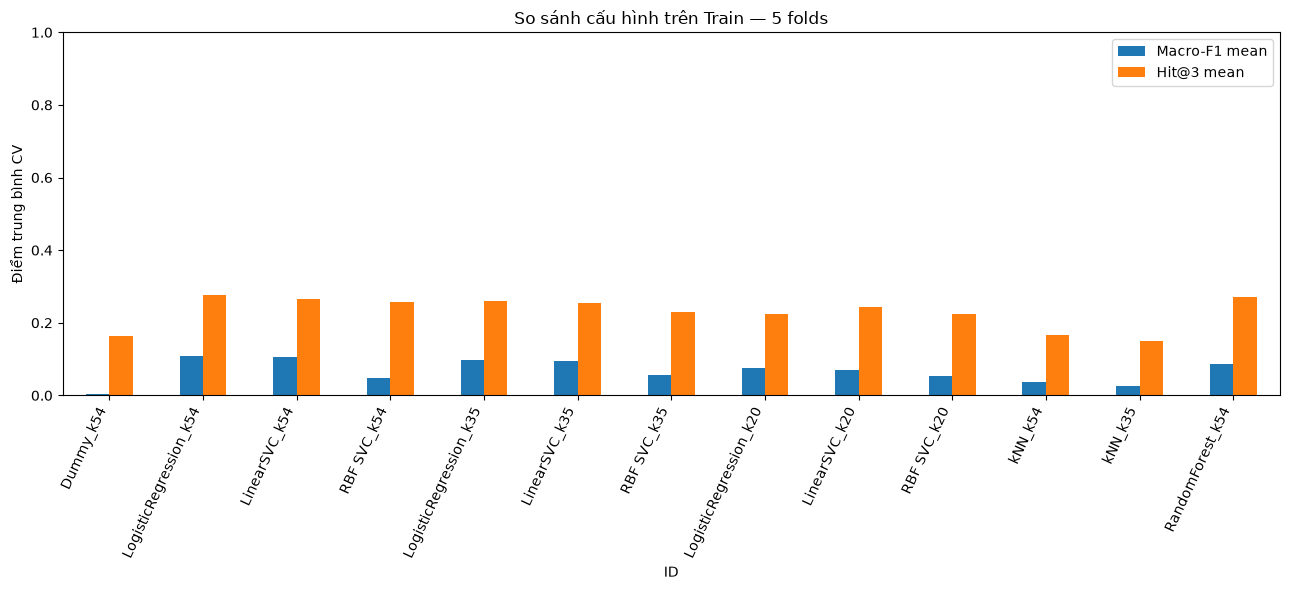

In [6]:
summary_rows = []
for c in configs:
    r = results[results['ID'].eq(c['ID'])]
    row = {k:c[k] for k in ['ID','Thuật toán','Scaler','Selector','k','Complexity']}
    for metric in ['Accuracy','Macro-F1','Balanced Accuracy','Hit@3']:
        row[metric+' mean'] = r[metric].mean()
        row[metric+' SD'] = r[metric].std(ddof=1)
    row['Eligible'] = not r['ConvergenceWarning'].any()
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows).set_index('ID')
display(summary.sort_values('Macro-F1 mean',ascending=False).round(4))
fig,ax = plt.subplots(figsize=(13,6))
summary[['Macro-F1 mean','Hit@3 mean']].plot.bar(ax=ax)
ax.set(ylabel='Điểm trung bình CV',title='So sánh cấu hình trên Train — 5 folds',ylim=(0,1))
plt.xticks(rotation=65,ha='right'); plt.tight_layout(); plt.show()


## 9. Chọn ứng viên theo quy tắc định trước
Không điều chỉnh các ngưỡng sau khi xem bảng. In rõ tập ứng viên còn lại ở từng bước và cấu hình chuyển sang Notebook 07; chưa fit toàn Train.

In [7]:
eligible = summary[summary['Eligible']].copy()
if eligible.empty:
    raise RuntimeError('Không có ứng viên hội tụ; dừng, không dùng Test.')
max_f1_id = eligible['Macro-F1 mean'].idxmax()
shortlist = eligible[eligible['Macro-F1 mean'] >= eligible['Macro-F1 mean'].max()-.005]
print('Gần nhất theo Macro-F1:',shortlist.index.tolist())
shortlist = shortlist[shortlist['Hit@3 mean'] >= shortlist['Hit@3 mean'].max()-.005]
print('Sau tiêu chí Hit@3:',shortlist.index.tolist())
shortlist = shortlist[shortlist['Macro-F1 SD'] <= shortlist['Macro-F1 SD'].min()+.005]
print('Sau độ ổn định:',shortlist.index.tolist())
chosen_id = shortlist.reset_index().sort_values(['Complexity','k','ID']).iloc[0]['ID']
chosen = summary.loc[chosen_id]
chosen_config = next(c for c in configs if c['ID']==chosen_id)
print('Macro-F1 mean cao nhất:',max_f1_id)
print('Cấu hình được chọn:',chosen_id)
display(chosen.to_frame('Giá trị'))
print('Pipeline dựng lại ở Notebook 07:',chosen_config['Pipeline'])
print('Tham số classifier đầy đủ:',chosen_config['Pipeline'].named_steps['classifier'].get_params())
print('Tham số scaler:',chosen_config['Pipeline'].named_steps['scaler'].get_params() if chosen_config['Scaler']!='Không' else 'passthrough')
print('Feature selector:',chosen_config['Selector'],'; k =',chosen_config['k'])
dummy = summary.loc['Dummy_k54']
print('Chênh lệch so với Dummy (điểm, chưa nhân 100):')
for metric in ['Accuracy','Macro-F1','Balanced Accuracy','Hit@3']:
    print(metric,chosen[metric+' mean']-dummy[metric+' mean'])
# Bảng đối chiếu k theo thuật toán: không chọn một k chung bằng Test.
display(summary.reset_index().pivot(index='Thuật toán',columns='k',values='Macro-F1 mean').round(4))
assert 'X_test' not in globals() and 'y_test' not in globals()
assert len(folds)==5 and len(results)==65
print('PASS: 65 fit Pipeline riêng; không có dữ liệu Test trong vòng huấn luyện/đánh giá.')

Gần nhất theo Macro-F1: ['LogisticRegression_k54', 'LinearSVC_k54']
Sau tiêu chí Hit@3: ['LogisticRegression_k54']
Sau độ ổn định: ['LogisticRegression_k54']
Macro-F1 mean cao nhất: LogisticRegression_k54
Cấu hình được chọn: LogisticRegression_k54
Pipeline dựng lại ở Notebook 07: Pipeline(steps=[('scaler', StandardScaler()), ('selector', 'passthrough'),
                ('classifier',
                 LogisticRegression(max_iter=10000, random_state=42))])
Tham số classifier đầy đủ: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 10000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Tham số scaler: {'copy': True, 'with_mean': True, 'with_std': True}
Feature selector: passthrough ; k = 54
Chênh lệch so với Dummy (điểm, chưa nhân 100):
Accuracy 0.0412113754443533
Macro-F1 0.10340043824765172
Balanced Accuracy 0.08308408762954217
Hit@

                                   Giá trị
Thuật toán              LogisticRegression
Scaler                      StandardScaler
Selector                       passthrough
k                                       54
Complexity                               1
Accuracy mean                     0.113713
Accuracy SD                       0.022073
Macro-F1 mean                     0.107497
Macro-F1 SD                       0.022942
Balanced Accuracy mean            0.113387
Balanced Accuracy SD              0.019731
Hit@3 mean                        0.276216
Hit@3 SD                          0.034477
Eligible                              True

k                       20      35      54
Thuật toán                                
Dummy                  NaN     NaN  0.0041
LinearSVC           0.0704  0.0961  0.1055
LogisticRegression  0.0757  0.0980  0.1075
RBF SVC             0.0530  0.0557  0.0488
RandomForest           NaN     NaN  0.0859
kNN                    NaN  0.0265  0.0378

## 10. Kết luận, giới hạn và chuẩn bị Notebook 07
Kết quả cụ thể và cấu hình đầy đủ được in ở phần 9. Chênh lệch mean và SD phải được đọc cùng nhau; 5 folds phụ thuộc nhau nên không suy diễn thành kiểm định thắng tuyệt đối. So sánh k trong bảng pivot cho biết lợi ích/hạn chế giảm chiều theo từng thuật toán, không chứng minh số câu tối ưu chung.

Không đo train scores hoặc learning curves nên chưa thể chẩn đoán overfitting trực tiếp. Kết quả validation thấp, chênh giữa các folds hoặc giữa các k có thể gợi ý mô hình yếu/không ổn định; không đủ để xác định nguyên nhân. Không đánh giá cao thấp bằng cách nhìn Test. Mỗi ngành chỉ khoảng 21–58 mẫu Train; validation mỗi lớp nhỏ nên F1 theo lớp và Macro-F1 dễ biến thiên. Kết quả chọn từ 13 cấu hình có thiên lệch lựa chọn, cần đánh giá độc lập.

Notebook 07 sẽ tái lập chính xác outer split: nhóm bằng tuple 54 đáp án gốc, factorize sort=False, SGKF(5,shuffle=True,random_state=42), fold đầu tiên. Dựng lại đúng Pipeline và tham số đã in ở phần 9, fit một lần trên toàn 800 mẫu Train, đánh giá duy nhất một lần trên 200 mẫu Test. Không sử dụng lại selector/scaler đã fit trong một fold. Chưa thực hiện bước này ở Notebook 06.

Nhãn là ngành đang học, không phải mức phù hợp nghề nghiệp; thiếu codebook và xác thực Holland. Không tuyên bố hệ thống tư vấn nghề nghiệp đã được xác minh. Không lưu model/scaler, không xuất CSV/JSON/PNG/HTML hoặc file phụ.

Phương pháp kiểm chứng: thực thi tuần tự tất cả code cell trong tiến trình Python 3.14 mới, lưu outputs và biểu đồ trực tiếp trong notebook. Dùng phương án được cho phép do lỗi quyền Jupyter Windows đã ghi nhận trước đó; chưa kiểm chứng bằng kernel Jupyter. Dừng sau Notebook 06, chờ duyệt.


### Nhận xét dựa trên kết quả thực tế
- **Ứng viên: StandardScaler → passthrough → LogisticRegression**, đủ 54 câu; C=1, solver='lbfgs', max_iter=10000, tol=0,0001, random_state=42; các tham số mặc định còn lại được in đầy đủ ở phần 9. Scaler mặc định with_mean=True, with_std=True. Không dùng feature selector; k=54. Đây cũng là cấu hình Macro-F1 trung bình cao nhất, phù hợp quy tắc đã định.
- Mean ± SD: Accuracy **0,1137 ± 0,0221**; Macro-F1 **0,1075 ± 0,0229**; Balanced Accuracy **0,1134 ± 0,0197**; Hit@3 **0,2762 ± 0,0345**.
- Dummy: Accuracy 0,0725; Macro-F1 0,0041; Balanced Accuracy 0,0303; Hit@3 0,1625. Ứng viên tăng khoảng **4,12 điểm phần trăm Accuracy**, **10,34 điểm phần trăm Macro-F1** và **11,37 điểm phần trăm Hit@3**. Tuy vượt baseline, mức điểm tuyệt đối còn thấp.
- LogisticRegression: Macro-F1 k54/k35/k20 = **0,1075/0,0980/0,0757**; LinearSVC = **0,1055/0,0961/0,0704**. Giảm câu chưa có lợi cho hai thuật toán này trong thí nghiệm cố định. LinearSVC k54 có mean gần LogisticRegression nhưng Hit@3 thấp hơn và SD Macro-F1 lớn hơn (0,0431 so với 0,0229).
- RBF SVC: k54/k35/k20 = **0,0488/0,0557/0,0530** Macro-F1; k35 có tăng so với k54 nhưng vẫn thấp hơn ứng viên. kNN k54/k35 = **0,0378/0,0265**; giảm còn 35 câu không cải thiện. Không có bằng chứng một k tối ưu cho mọi thuật toán.
- RandomForest k54 có Accuracy cao nhất **0,1251**, nhưng Macro-F1 **0,0859**, Balanced Accuracy **0,0971**; do đó không được chọn chỉ theo Accuracy. Chênh giữa Accuracy và Macro-F1 ở RBF SVC/kNN gợi ý dự đoán các lớp chưa đồng đều, cần đánh giá theo lớp ở bước cuối; chưa có bảng theo lớp để kết luận ngành nào bị bỏ sót.
- Validation mỗi lớp có tối thiểu **4 mẫu**, làm ước lượng theo lớp dễ dao động. Chưa đo training scores nên không khẳng định overfitting từ CV này. Không đổi seed, nhãn hoặc tăng thí nghiệm để cải thiện điểm.
- **7/7 code cell**, **13 cấu hình × 5 folds = 65 fit** thành công. Có **15 FutureWarning** từ tham số probability của SVC trong sklearn 1.9.1; không có ConvergenceWarning. Các cảnh báo được giữ đầy đủ trong outputs. SVC dùng decision_function, không diễn giải thành xác suất; chưa thay đổi cấu hình sau khi xem kết quả.
- Đã kiểm tra SHA-256 workbook và Notebook 00–05 không đổi trong quá trình chạy. Không đánh giá Test; chưa fit Pipeline cuối trên toàn Train. Dừng để duyệt Notebook 06.
